# 48. Benthos and Bottom Sediment Data Overview (2003-2023)

This notebook provides a comprehensive overview, cleaning pipeline, and visual analysis of the new datasets:
1. **Benthos Data:** `data/raw/benthos_data/benthos_2023.xlsx`
2. **Bottom Sediment Data:** `data/raw/benthos_data/bottom_2023.xlsx`

The analysis follows these key phases:
- **Data Loading & Cleaning:** Standardizing headers, parsing dates, converting DMS coordinates to decimal degrees, correcting shifted rows, and handling qualitative flags (e.g., `+`, `G`, `< 0.01`).
- **Benthos Metric Computation:** Calculating Species Richness, Abundance, Biomass, and Shannon-Wiener Diversity index ($H'$) per sample.
- **Data Merging:** Joining biological and physical-chemical datasets.
- **Exploratory Data Analysis & Visualization:** Analyzing temporal trends, regional spatial patterns (overlaid on Seto Inland Sea boundary shapefiles), environmental correlations, and taxonomic composition.


## Setup and Imports
We load the necessary packages, apply the standard project styling, and set up path directories.


In [1]:
import sys
from pathlib import Path
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from scripts.paths import ProjectPaths

# Apply the project's matplotlib stylesheet
style_path = ProjectPaths.PROJECT_ROOT / 'project_style.mplstyle'
if style_path.exists():
    plt.style.use(str(style_path))
    print(f'Applied project style: {style_path}')
else:
    sns.set_theme(style='ticks')
    print('Warning: project_style.mplstyle not found, using seaborn fallback.')

# Ensure output directory for figures exists
output_fig_dir = ProjectPaths.FIGURES_DIR / 'benthos_sediment_overview'
output_fig_dir.mkdir(parents=True, exist_ok=True)
print(f'Figures will be saved in: {output_fig_dir}')


Applied project style: /home/reyha/SIS_Analysis_WSL/project_style.mplstyle
Figures will be saved in: /home/reyha/SIS_Analysis_WSL/figures/benthos_sediment_overview


## Dataset Overview: Shape, Structure, and Coverage

Before diving into cleaning, we examine the raw characteristics of the datasets:
1. **Benthos Data (`benthos_2023.xlsx`):** A wide dataset with 254 columns containing up to 62 species' taxonomy, counts, and biomass wet weights per row.
2. **Bottom Sediment Data (`bottom_2023.xlsx`):** A dataset containing 51 columns detailing sediment grain size distribution, physicochemical indicators (pH, ORP, COD, TN, TP, TOC, Sulfides), coordinates, and weather conditions.

/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")
/tmp/ipykernel_30927/3984092736.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=chem_vars, y=completeness, ax=axes[1], palette='Blues_r')
/tmp/ipykernel_30927/3984092736.py:47: UserWarning: Glyph 30827 (\N{CJK UNIFIED IDEOGRAPH-786B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_30927/3984092736.py:47: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_30927/3984092736.py:47: UserWarning: Glyph 29289 (\N{CJK UNIFIED IDEOGRAPH-7269}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ip

=== Benthos Raw Dataset Structure ===
Shape: 1572 rows x 254 columns
Time period covered: 2003 to 2023
Prefectures covered (pref codes): [np.float64(4.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(23.0), np.float64(24.0), np.float64(27.0), np.float64(28.0), np.float64(30.0), np.float64(34.0), np.float64(35.0), np.float64(37.0), np.float64(38.0), np.float64(40.0), np.float64(41.0), np.float64(42.0), np.float64(43.0), np.float64(44.0), np.float64(46.0)]

=== Bottom Sediment Raw Dataset Structure ===
Shape: 1852 rows x 51 columns
Time period covered: 1991 to 2023
Prefectures covered (pref codes): [np.int64(12), np.int64(13), np.int64(14), np.int64(23), np.int64(24), np.int64(27), np.int64(28), np.int64(30), np.int64(34), np.int64(35), np.int64(37), np.int64(38), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(46)]


/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 30827 (\N{CJK UNIFIED IDEOGRAPH-786B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21270 (\N{CJK UNIFIED IDEOGRAPH-5316}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 29289 (\N{CJK UNIFIED IDEOGRAPH-7269}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


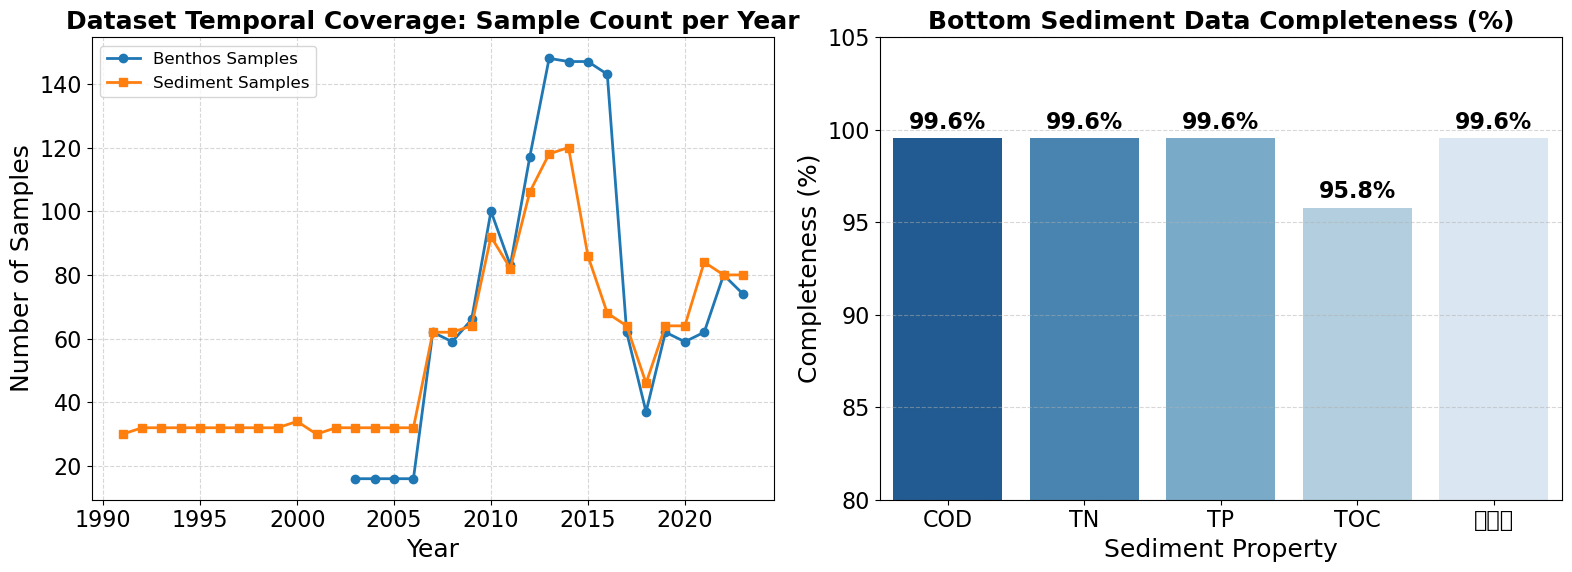

In [2]:
benthos_path = ProjectPaths.DATA_DIR / 'raw' / 'benthos_data' / 'benthos_2023.xlsx'
bottom_path = ProjectPaths.DATA_DIR / 'raw' / 'benthos_data' / 'bottom_2023.xlsx'

# Load raw datasets for overview
df_benthos_raw_ov = pd.read_excel(benthos_path, skiprows=1)
df_bottom_raw_ov = pd.read_excel(bottom_path, sheet_name='底質_累積2023')

# Print basic shape and column structures
print("=== Benthos Raw Dataset Structure ===")
print(f"Shape: {df_benthos_raw_ov.shape[0]} rows x {df_benthos_raw_ov.shape[1]} columns")
print(f"Time period covered: {df_benthos_raw_ov['年度'].min()} to {df_benthos_raw_ov['年度'].max()}")
print(f"Prefectures covered (pref codes): {sorted(list(df_benthos_raw_ov['県コード'].dropna().unique()))}")

print("\n=== Bottom Sediment Raw Dataset Structure ===")
print(f"Shape: {df_bottom_raw_ov.shape[0]} rows x {df_bottom_raw_ov.shape[1]} columns")
print(f"Time period covered: {df_bottom_raw_ov['年度'].min()} to {df_bottom_raw_ov['年度'].max()}")
print(f"Prefectures covered (pref codes): {sorted(list(df_bottom_raw_ov['県コード'].dropna().unique()))}")

# Visualize sample counts over time and completeness of key variables
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Samples collected per year
benthos_by_year = df_benthos_raw_ov.groupby('年度').size()
bottom_by_year = df_bottom_raw_ov.groupby('年度').size()

axes[0].plot(benthos_by_year.index, benthos_by_year.values, marker='o', label='Benthos Samples', color='#1f77b4', linewidth=2)
axes[0].plot(bottom_by_year.index, bottom_by_year.values, marker='s', label='Sediment Samples', color='#ff7f0e', linewidth=2)
axes[0].set_title('Dataset Temporal Coverage: Sample Count per Year')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Number of Samples')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Data completeness of key sediment variables
chem_vars = ['COD', 'TN', 'TP', 'TOC', '硫化物']
completeness = [df_bottom_raw_ov[var].notna().mean() * 100 for var in chem_vars]

sns.barplot(x=chem_vars, y=completeness, ax=axes[1], palette='Blues_r')
axes[1].set_title('Bottom Sediment Data Completeness (%)')
axes[1].set_xlabel('Sediment Property')
axes[1].set_ylabel('Completeness (%)')
axes[1].set_ylim(80, 105)
for i, val in enumerate(completeness):
    axes[1].text(i, val + 0.5, f"{val:.1f}%", ha='center', fontweight='bold')
axes[1].grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(output_fig_dir / 'dataset_overview_coverage.png', dpi=300)
plt.show()


### Sampling Month Distribution

We visualize the monthly distribution of samples for both datasets to understand the seasonal timing of surveys.

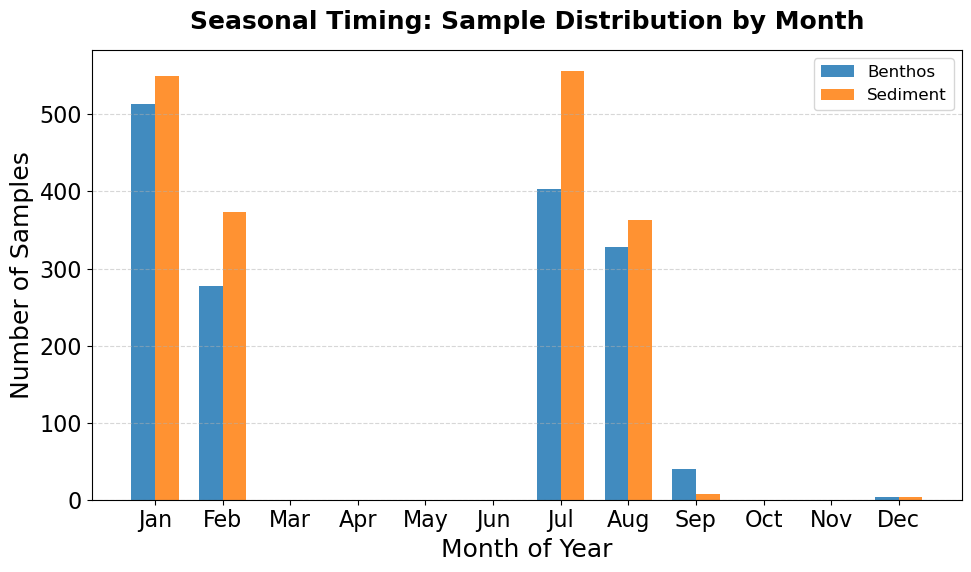

In [3]:
# Extract and count samples by month for both datasets
benthos_months_counts = pd.to_datetime(df_benthos_raw_ov['調査年月日'], errors='coerce').dt.month.value_counts().reindex(range(1, 13), fill_value=0)
bottom_months_counts = df_bottom_raw_ov['月'].value_counts().reindex(range(1, 13), fill_value=0)

df_months_plot = pd.DataFrame({
    'Month': range(1, 13),
    'Benthos': benthos_months_counts.values,
    'Sediment': bottom_months_counts.values
})

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(1, 13)
width = 0.35

# Grouped bar chart
ax.bar(x - width/2, df_months_plot['Benthos'], width, label='Benthos', color='#1f77b4', alpha=0.85)
ax.bar(x + width/2, df_months_plot['Sediment'], width, label='Sediment', color='#ff7f0e', alpha=0.85)

ax.set_title('Seasonal Timing: Sample Distribution by Month', pad=15)
ax.set_xlabel('Month of Year')
ax.set_ylabel('Number of Samples')
ax.set_xticks(x)
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax.legend()
ax.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(output_fig_dir / 'sampling_month_distribution.png', dpi=300)
plt.show()


## Spatial Distribution of Sampling Stations

We map the sampling locations for both the bottom sediment and benthos datasets using the simplified nation-wide prefectural boundary shapefile. Because coordinates are only recorded in the bottom sediment dataset, benthos stations are mapped by matching their prefecture codes and station numbers to the bottom sediment station list (mapping 97.2% of benthos records).

ERROR 1: PROJ: proj_create_from_database: Open of /home/reyha/miniconda3/envs/sis_analysis/share/proj failed


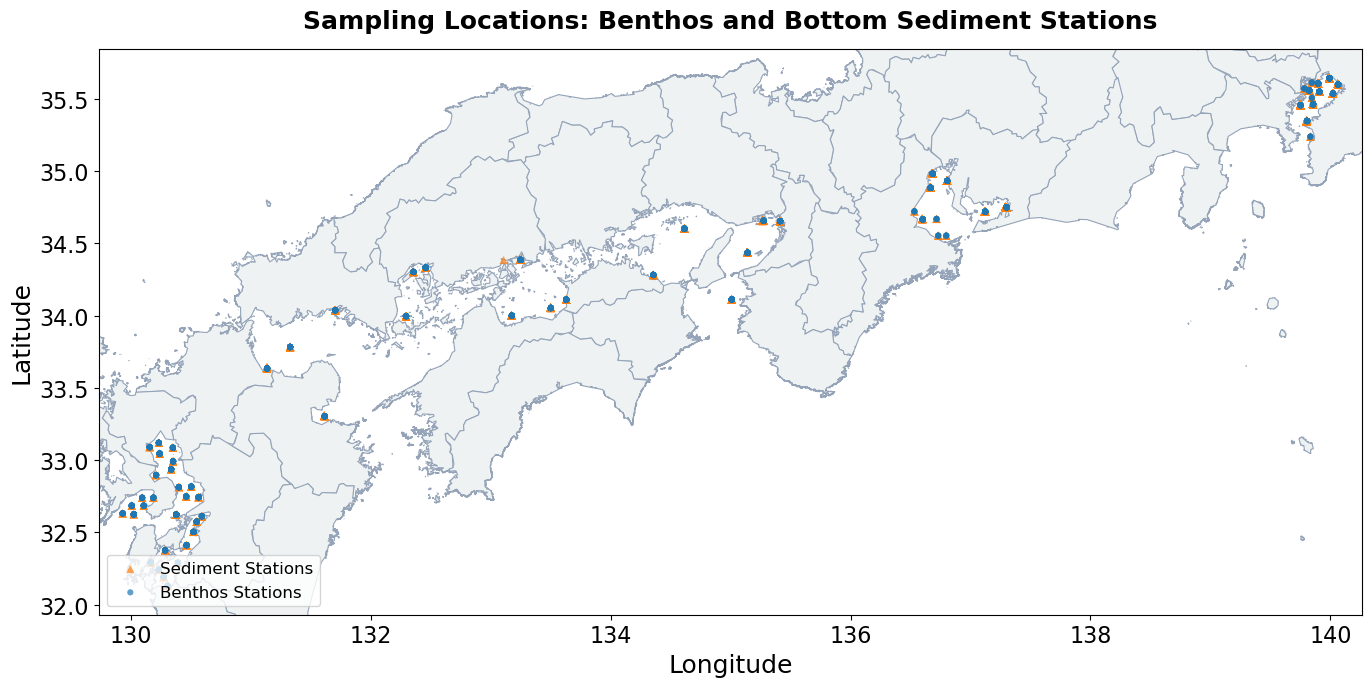

In [4]:
import geopandas as gpd

# 1. Convert bottom sediment coordinates
def dms_to_dd(d, m, s):
    return d + m / 60.0 + s / 3600.0

df_bottom_raw_ov['lat'] = dms_to_dd(df_bottom_raw_ov['緯度_度'], df_bottom_raw_ov['緯度_分'], df_bottom_raw_ov['緯度_秒'])
df_bottom_raw_ov['lon'] = dms_to_dd(df_bottom_raw_ov['経度_度'], df_bottom_raw_ov['経度_分'], df_bottom_raw_ov['経度_秒'])

# 2. Build coordinate lookup maps from bottom sediment data
coords_map_serial = df_bottom_raw_ov.dropna(subset=['lat', 'lon']).groupby(['県コード', '連番'])[['lat', 'lon']].first().to_dict('index')
coords_map_prefnum = df_bottom_raw_ov.dropna(subset=['lat', 'lon']).groupby(['県コード', '県番号'])[['lat', 'lon']].first().to_dict('index')

# 3. Map coordinates to benthos data
benthos_lats = []
benthos_lons = []
for idx, row in df_benthos_raw_ov.iterrows():
    key_serial = (row['県コード'], row['連番'])
    key_prefnum = (row['県コード'], row['県番号'])
    if key_serial in coords_map_serial:
        benthos_lats.append(coords_map_serial[key_serial]['lat'])
        benthos_lons.append(coords_map_serial[key_serial]['lon'])
    elif key_prefnum in coords_map_prefnum:
        benthos_lats.append(coords_map_prefnum[key_prefnum]['lat'])
        benthos_lons.append(coords_map_prefnum[key_prefnum]['lon'])
    else:
        benthos_lats.append(None)
        benthos_lons.append(None)

df_benthos_raw_ov['lat'] = benthos_lats
df_benthos_raw_ov['lon'] = benthos_lons
df_benthos_mapped = df_benthos_raw_ov.dropna(subset=['lat', 'lon'])

# 4. Load Japan boundary shapefile
japan_boundary_path = ProjectPaths.BOUNDARIES_DIR / "Whole nation administrative boundary" / "N03-20240101_prefecture(simplified0.01).shp"
gdf_boundary = gpd.read_file(japan_boundary_path)
if gdf_boundary.crs != "EPSG:4326":
    gdf_boundary = gdf_boundary.to_crs("EPSG:4326")

# 5. Create GeoDataFrames for plotting
gdf_bottom_stations = gpd.GeoDataFrame(
    df_bottom_raw_ov.dropna(subset=['lat', 'lon']),
    geometry=gpd.points_from_xy(df_bottom_raw_ov.dropna(subset=['lat', 'lon'])['lon'], df_bottom_raw_ov.dropna(subset=['lat', 'lon'])['lat']),
    crs="EPSG:4326"
)
gdf_benthos_stations = gpd.GeoDataFrame(
    df_benthos_mapped,
    geometry=gpd.points_from_xy(df_benthos_mapped['lon'], df_benthos_mapped['lat']),
    crs="EPSG:4326"
)

# 6. Plot the map
fig, ax = plt.subplots(figsize=(14, 8))
gdf_boundary.plot(ax=ax, color='#eef2f3', edgecolor='#94a3b8', linewidth=0.8)

# Plot sediment stations as orange, and benthos as blue
gdf_bottom_stations.plot(ax=ax, color='#ff7f0e', marker='^', markersize=35, label='Sediment Stations', alpha=0.7, edgecolor='none')
gdf_benthos_stations.plot(ax=ax, color='#1f77b4', marker='o', markersize=20, label='Benthos Stations', alpha=0.7, edgecolor='none')

# Set map boundaries to crop to Seto Inland Sea
min_lon = min(df_bottom_raw_ov['lon'].min(), df_benthos_mapped['lon'].min()) - 0.2
max_lon = max(df_bottom_raw_ov['lon'].max(), df_benthos_mapped['lon'].max()) + 0.2
min_lat = min(df_bottom_raw_ov['lat'].min(), df_benthos_mapped['lat'].min()) - 0.2
max_lat = max(df_bottom_raw_ov['lat'].max(), df_benthos_mapped['lat'].max()) + 0.2

ax.set_xlim(min_lon, max_lon)
ax.set_ylim(min_lat, max_lat)

ax.set_title('Sampling Locations: Benthos and Bottom Sediment Stations', pad=15)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.legend(loc='lower left')
plt.tight_layout()
plt.savefig(output_fig_dir / 'sampling_locations_map.png', dpi=300)
plt.show()


## 1. Load and Process Bottom Sediment Data
We read the sheet `底質_累積2023` from `bottom_2023.xlsx`, combine the date fields, and convert latitude/longitude from degrees-minutes-seconds (DMS) to decimal degrees.


In [5]:
bottom_path = ProjectPaths.DATA_DIR / 'raw' / 'benthos_data' / 'bottom_2023.xlsx'
print(f'Loading bottom sediment data from {bottom_path}...')
df_bottom_raw = pd.read_excel(bottom_path, sheet_name='底質_累積2023')
print(f'Raw bottom sediment shape: {df_bottom_raw.shape}')


Loading bottom sediment data from /home/reyha/SIS_Analysis_WSL/data/raw/benthos_data/bottom_2023.xlsx...


Raw bottom sediment shape: (1852, 51)


/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


### Parsing Dates and Coordinates
We construct a datetime object from the individual date columns and convert the coordinate fields into decimal degrees.


In [6]:
df_bottom = df_bottom_raw.copy()

# 1. Parse survey date
df_bottom['date'] = pd.to_datetime(
    df_bottom[['年', '月', '日']].rename(columns={'年': 'year', '月': 'month', '日': 'day'}),
    errors='coerce'
)

# 2. Convert DMS to Decimal Degrees
def dms_to_dd(d, m, s):
    return d + m / 60.0 + s / 3600.0

df_bottom['lat'] = dms_to_dd(df_bottom['緯度_度'], df_bottom['緯度_分'], df_bottom['緯度_秒'])
df_bottom['lon'] = dms_to_dd(df_bottom['経度_度'], df_bottom['経度_分'], df_bottom['経度_秒'])

# 3. Coerce numeric columns
numeric_cols = [
    '礫分', '砂分', '粘土分', 'pH', 'ORP', '乾燥減量', 
    '強熱減量', 'COD', 'TN', 'TP', 'TOC', '硫化物', '水深'
]
for col in numeric_cols:
    df_bottom[col] = pd.to_numeric(df_bottom[col], errors='coerce')

print('Cleaned bottom sediment sample:')
display(df_bottom[['date', 'lat', 'lon', 'COD', 'TN', 'TP', 'TOC', '硫化物']].head(3))


Cleaned bottom sediment sample:


,date,lat,lon,COD,TN,TP,TOC,硫化物
0,1991-08-06,35.608333,139.898333,13.9,1.47,0.58,11.3,0.57
1,1992-02-05,35.608333,139.898333,3.8,0.49,0.42,4.1,0.06
2,1991-08-06,35.643889,139.993333,4.4,0.47,0.29,2.6,0.08


## 2. Load and Clean Benthos Data
We read the sheet `底生生物_累積2023` from `benthos_2023.xlsx`. We skip the first row (since it is a note cell) and use the second row as the header.


In [7]:
benthos_path = ProjectPaths.DATA_DIR / 'raw' / 'benthos_data' / 'benthos_2023.xlsx'
print(f'Loading benthos data from {benthos_path}...')
df_benthos_raw = pd.read_excel(benthos_path, skiprows=1)
print(f'Raw benthos shape: {df_benthos_raw.shape}')


Loading benthos data from /home/reyha/SIS_Analysis_WSL/data/raw/benthos_data/benthos_2023.xlsx...


Raw benthos shape: (1572, 254)


/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


### Correcting Data Typo & Column Shifts
Before pivoting, we correct the survey date typo (year `2109` -> `2019`) and programmatically realign the columns for rows `569` and `605` which suffer from cell shifts.


In [8]:
df_benthos = df_benthos_raw.copy()

# 1. Correct future date typo (Row 1252)
typo_idx = df_benthos[df_benthos['調査年月日'].astype(str).str.startswith('2109')].index
if not typo_idx.empty:
    df_benthos.loc[typo_idx, '調査年月日'] = pd.to_datetime('2019-07-10')
    print(f'Corrected date typo for index {list(typo_idx)}')

# 2. Parse survey date
df_benthos['date'] = pd.to_datetime(df_benthos['調査年月日'], errors='coerce')

# 3. Fix column shift for row 569
df_benthos.loc[569, '個体数8'] = 1
df_benthos.loc[569, '湿重量8'] = 0.12
df_benthos.loc[569, '学名9'] = 'Pinnixa rathbuni'
df_benthos.loc[569, '和名9'] = 'ﾗｽﾊﾞﾝﾏﾒｶﾞﾆ'
df_benthos.loc[569, '個体数9'] = 22
df_benthos.loc[569, '湿重量9'] = 1.18
df_benthos.loc[569, '学名10'] = 'Cancer sp.'
df_benthos.loc[569, '和名10'] = 'ｲﾁｮｳｶﾞﾆ属'
df_benthos.loc[569, '個体数10'] = 1
df_benthos.loc[569, '湿重量10'] = 2.92
print('Fixed column shifts for Row 569.')

# 4. Fix column shift for row 605
df_benthos.loc[605, '個体数8'] = 70
df_benthos.loc[605, '湿重量8'] = 0.2
df_benthos.loc[605, '学名9'] = 'Liljeborgia sp.'
df_benthos.loc[605, '和名9'] = 'ﾄｹﾞﾖｺｴﾋﾞ属'
df_benthos.loc[605, '個体数9'] = np.nan
df_benthos.loc[605, '湿重量9'] = np.nan
print('Fixed column shifts for Row 605.')


Corrected date typo for index [1252]
Fixed column shifts for Row 569.
Fixed column shifts for Row 605.


### Reshaping Wide to Long (Tidy) Format
The original benthos sheet is in a wide layout with 62 species columns per row. We melt these columns to create a tidy occurrence-level dataset.


In [9]:
benthos_melted = []
for i in range(1, 63):
    cols = ['年度', '県コード', '連番', '県番号', 'date', '採泥面積', f'学名{i}', f'和名{i}', f'個体数{i}', f'湿重量{i}']
    sub = df_benthos[cols].copy()
    sub.columns = ['年度', '県コード', '連番', '県番号', 'date', '採泥面積', 'species_sci', 'species_jap', 'abundance_raw', 'weight_raw']
    sub['species_index'] = i
    benthos_melted.append(sub)

df_benthos_long = pd.concat(benthos_melted, ignore_index=True)
# Drop rows where species is completely blank
df_benthos_long = df_benthos_long.dropna(subset=['species_sci', 'species_jap'], how='all')

# Ensure clean string formatting and filter out string representations of nan
df_benthos_long['species_sci'] = df_benthos_long['species_sci'].astype(str).str.strip()
df_benthos_long['species_jap'] = df_benthos_long['species_jap'].astype(str).str.strip()
df_benthos_long = df_benthos_long[~df_benthos_long['species_sci'].isin(['nan', '', 'None', 'None.1'])]

print(f'Melted long-format shape: {df_benthos_long.shape}')


Melted long-format shape: (27654, 11)


### Cleaning Species Abundance and Biomass Weights
We parse quantitative values, mapping qualitative qualifiers based on ecological standards:
- **Abundance:** `+`/`＋`/`G` are mapped to `1.0`.
- **Wet Weight:** `+`/`+  `/`< 0.01`/`<0.01` (trace) are mapped to `0.005` (half the detection limit). Hyphens (`-`/`－`/`    -`) are mapped to `0.0`.


In [10]:
def clean_abundance(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip()
    if val_str in ['+', '＋', 'G']:
        return 1.0
    try:
        return float(val_str)
    except ValueError:
        return np.nan

def clean_weight(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip()
    if val_str in ['-', '－', '    -', '   -']:
        return 0.0
    if val_str in ['+', '+  ', '< 0.01', '<0.01']:
        return 0.005
    try:
        return float(val_str)
    except ValueError:
        return np.nan

df_benthos_long['abundance'] = df_benthos_long['abundance_raw'].apply(clean_abundance)
df_benthos_long['weight'] = df_benthos_long['weight_raw'].apply(clean_weight)

# Also clean mud sampling area
df_benthos_long['採泥面積'] = pd.to_numeric(
    df_benthos_long['採泥面積'].astype(str).str.replace('-', '').str.strip(), 
    errors='coerce'
)

print('Cleaned species occurrence sample:')
display(df_benthos_long[['date', 'species_sci', 'species_jap', 'abundance', 'weight']].head(3))


Cleaned species occurrence sample:


,date,species_sci,species_jap,abundance,weight
0,2003-08-05,ACTINIARIA,ｲｿｷﾞﾝﾁｬｸ目,1.0,0.070
1,2004-02-03,POLYCLADIDA,ﾋﾗﾑｼ目,1.0,0.005
2,2003-08-05,NEMERTINEA,紐形動物門,9.0,0.030


## 3. Compute Benthos Diversity and Abundance Metrics
For each unique survey sample, we pool the species occurrences (aggregating duplicates if they occur) and calculate:
- **Species Richness ($S$):** Number of distinct species.
- **Total Abundance ($N$):** Sum of individuals.
- **Total Biomass ($B$):** Sum of wet weight.
- **Shannon-Wiener Index ($H'$):**
  $$H' = - \sum_{i=1}^{S} p_i \ln p_i$$
  where $p_i = n_i / N$


In [11]:
# First step: group by sample and species to combine any duplicates
sample_keys = ['年度', '県コード', '連番', 'date', '採泥面積']
df_species_agg = df_benthos_long.groupby(sample_keys + ['species_sci', 'species_jap']).agg({
    'abundance': 'sum',
    'weight': 'sum'
}).reset_index()

# Second step: compute sample-level metrics
def compute_shannon(abundances):
    ab = abundances.dropna()
    ab = ab[ab > 0]
    if len(ab) == 0:
        return 0.0
    total = ab.sum()
    p = ab / total
    return -np.sum(p * np.log(p))

df_benthos_summary = df_species_agg.groupby(sample_keys).agg(
    richness=('species_sci', 'nunique'),
    total_abundance=('abundance', 'sum'),
    total_biomass=('weight', 'sum'),
    shannon_index=('abundance', compute_shannon)
).reset_index()

print(f'Computed metrics for {len(df_benthos_summary)} benthos samples:')
display(df_benthos_summary.head(3))


Computed metrics for 1131 benthos samples:


,年度,県コード,連番,date,採泥面積,richness,total_abundance,total_biomass,shannon_index
0,2007,12.0,2,2007-08-02,0.1,1,2.0,0.00,-0.000000
1,2007,12.0,2,2008-02-05,0.1,13,246.0,170.24,1.185491
2,2007,12.0,4,2007-08-02,0.1,1,15.0,0.14,-0.000000


## 4. Merge Benthos and Sediment Data
We merge the biological sample metrics and physical-chemical sediment quality data using the primary keys: prefecture code (`県コード`), serial number (`連番`), and `date`.


In [12]:
df_merged = pd.merge(
    df_benthos_summary,
    df_bottom,
    on=['県コード', '連番', 'date'],
    suffixes=('_benthos', '_sediment')
)
print(f'Merged dataset shape: {df_merged.shape}')
print(f'Overlap from Benthos samples: {len(df_merged)} / {len(df_benthos_summary)} ({len(df_merged)/len(df_benthos_summary)*100:.1f}%)')


Merged dataset shape: (821, 60)
Overlap from Benthos samples: 821 / 1131 (72.6%)


## 5. Visualizations & Analysis
### A. Spatial Distribution of Species Richness
We map the locations of the merged samples in the Seto Inland Sea, overlaying species richness on the regional boundary.


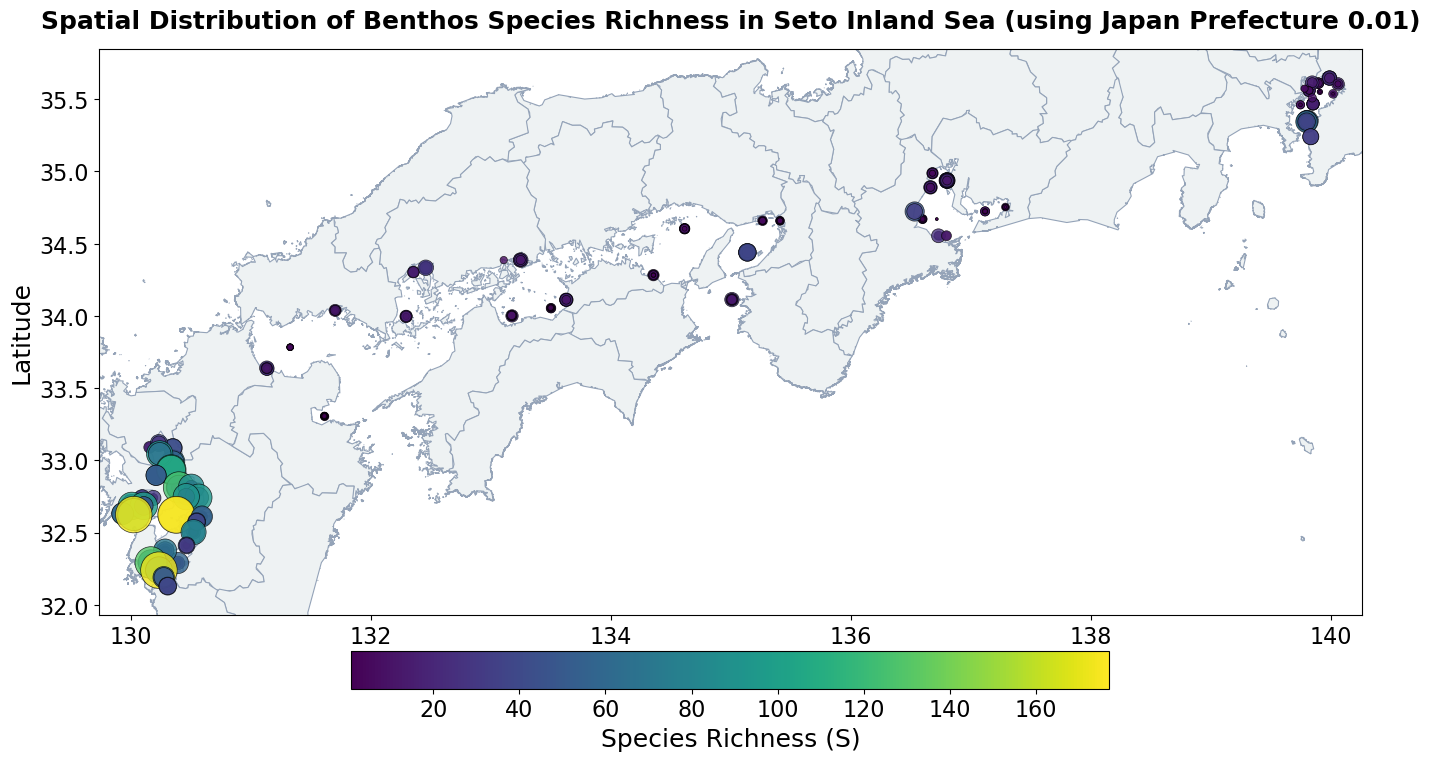

In [13]:
boundary_path = ProjectPaths.BOUNDARIES_DIR / 'Whole nation administrative boundary' / 'N03-20240101_prefecture(simplified0.01).shp'
if boundary_path.exists():
    gdf_boundary = gpd.read_file(boundary_path)
    if gdf_boundary.crs != 'EPSG:4326':
        gdf_boundary = gdf_boundary.to_crs('EPSG:4326')
    
    # Create GeoDataFrame of samples
    gdf_samples = gpd.GeoDataFrame(
        df_merged,
        geometry=gpd.points_from_xy(df_merged['lon'], df_merged['lat']),
        crs='EPSG:4326'
    )
    
    fig, ax = plt.subplots(figsize=(14, 8))
    gdf_boundary.plot(ax=ax, color='#eef2f3', edgecolor='#94a3b8', linewidth=0.8)
    
    # Plot samples colored by species richness
    scatter = gdf_samples.plot(
        ax=ax, 
        column='richness', 
        cmap='viridis', 
        legend=True, 
        legend_kwds={'label': 'Species Richness (S)', 'orientation': 'horizontal', 'shrink': 0.6, 'pad': 0.05},
        markersize=df_merged['richness'] * 4, 
        alpha=0.8, 
        edgecolor='black', 
        linewidth=0.5
    )
    
    # Set map limits to zoom into the Seto Inland Sea bounding box
    min_lon, max_lon = df_merged['lon'].min() - 0.2, df_merged['lon'].max() + 0.2
    min_lat, max_lat = df_merged['lat'].min() - 0.2, df_merged['lat'].max() + 0.2
    ax.set_xlim(min_lon, max_lon)
    ax.set_ylim(min_lat, max_lat)
    
    ax.set_title('Spatial Distribution of Benthos Species Richness in Seto Inland Sea (using Japan Prefecture 0.01)', pad=15)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    plt.tight_layout()
    plt.savefig(output_fig_dir / 'spatial_species_richness.png', dpi=300)
    plt.show()
else:
    print(f'Boundary file not found at {boundary_path}. Skipping spatial map.')


### B. Temporal Trends (2003-2023)
We trace the annual averages of benthos biological metrics and corresponding sediment chemistry.


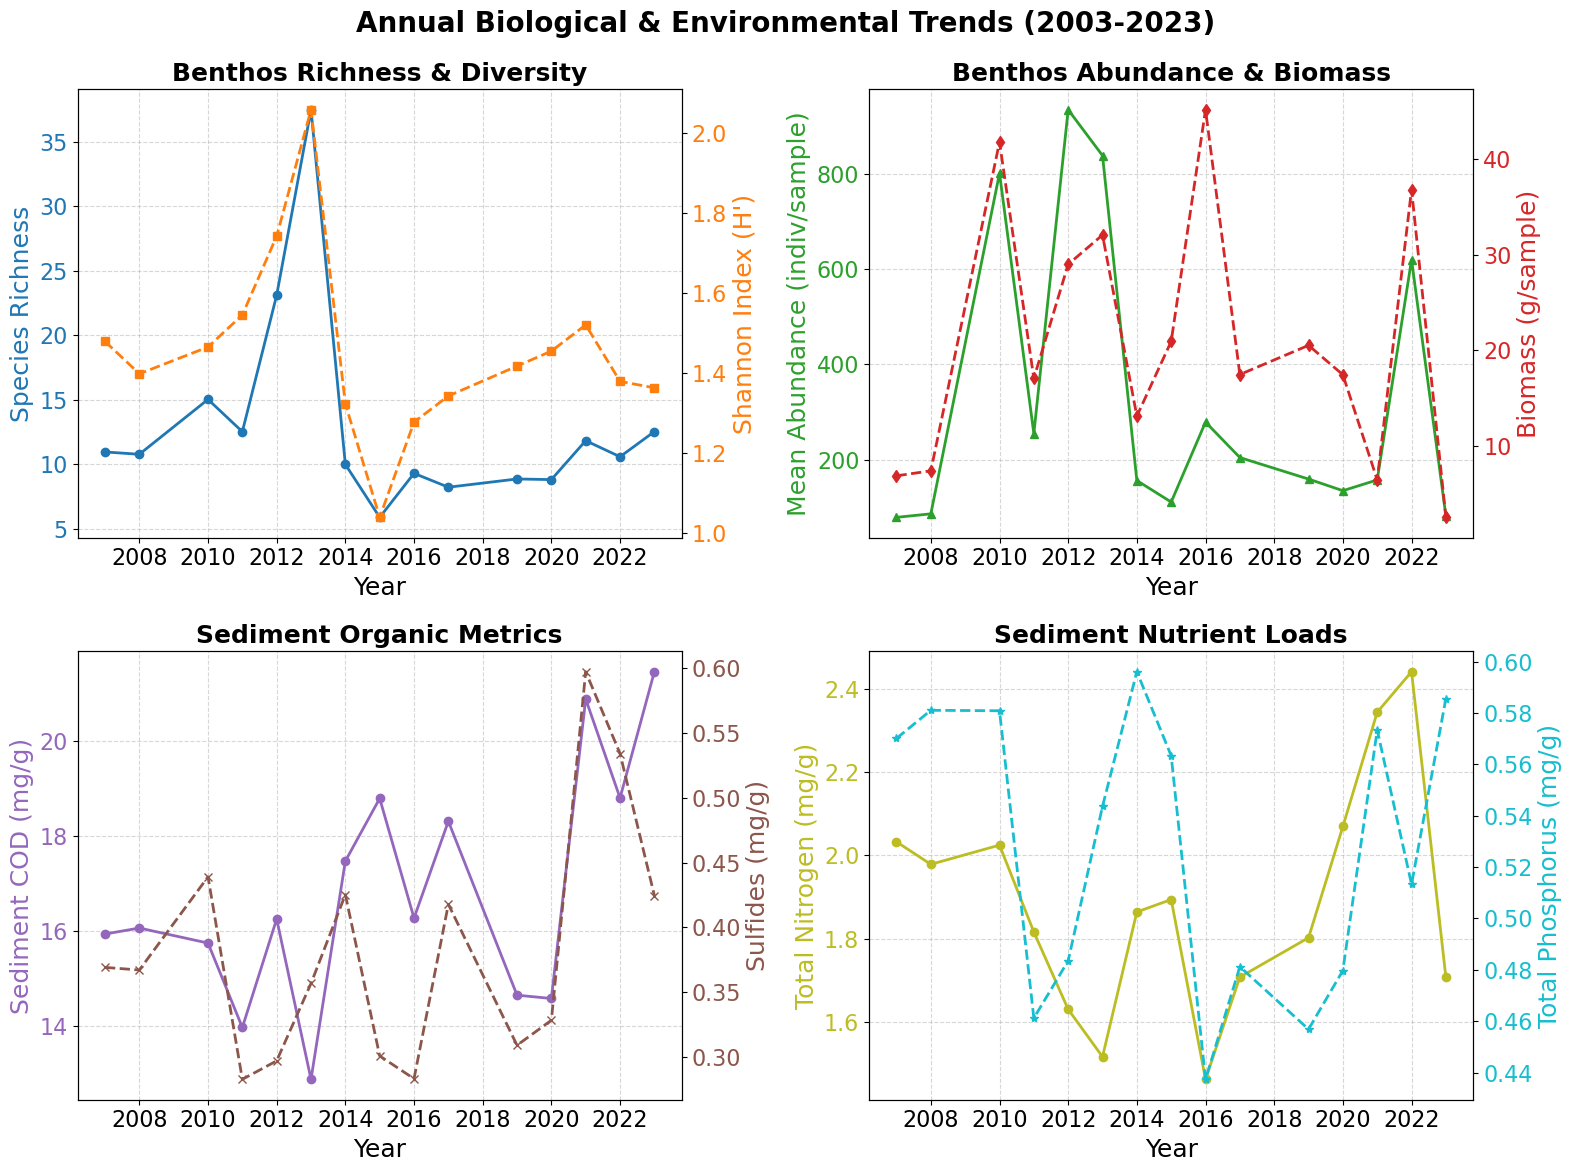

In [14]:
annual_summary = df_merged.groupby('年度_benthos').agg({
    'richness': 'mean',
    'total_abundance': 'mean',
    'total_biomass': 'mean',
    'shannon_index': 'mean',
    'COD': 'mean',
    'TN': 'mean',
    'TP': 'mean',
    '硫化物': 'mean'
}).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Annual Biological & Environmental Trends (2003-2023)', y=0.98)

# 1. Richness & Shannon Index
ax1 = axes[0, 0]
color1 = '#1f77b4'
ax1.plot(annual_summary['年度_benthos'], annual_summary['richness'], color=color1, marker='o', linewidth=2, label='Mean Richness')
ax1.set_xlabel('Year')
ax1.set_ylabel('Species Richness', color=color1)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_title('Benthos Richness & Diversity')
ax1.grid(True, linestyle='--', alpha=0.5)

ax1_twin = ax1.twinx()
color2 = '#ff7f0e'
ax1_twin.plot(annual_summary['年度_benthos'], annual_summary['shannon_index'], color=color2, marker='s', linestyle='--', linewidth=2, label='Shannon (H\'\)')
ax1_twin.set_ylabel('Shannon Index (H\')', color=color2)
ax1_twin.tick_params(axis='y', labelcolor=color2)

# 2. Abundance & Biomass
ax2 = axes[0, 1]
color3 = '#2ca02c'
ax2.plot(annual_summary['年度_benthos'], annual_summary['total_abundance'], color=color3, marker='^', linewidth=2, label='Abundance')
ax2.set_xlabel('Year')
ax2.set_ylabel('Mean Abundance (indiv/sample)', color=color3)
ax2.tick_params(axis='y', labelcolor=color3)
ax2.set_title('Benthos Abundance & Biomass')
ax2.grid(True, linestyle='--', alpha=0.5)

ax2_twin = ax2.twinx()
color4 = '#d62728'
ax2_twin.plot(annual_summary['年度_benthos'], annual_summary['total_biomass'], color=color4, marker='d', linestyle='--', linewidth=2, label='Biomass')
ax2_twin.set_ylabel('Biomass (g/sample)', color=color4)
ax2_twin.tick_params(axis='y', labelcolor=color4)

# 3. Sediment Organic load (COD & Sulfides)
ax3 = axes[1, 0]
color5 = '#9467bd'
ax3.plot(annual_summary['年度_benthos'], annual_summary['COD'], color=color5, marker='o', linewidth=2, label='COD')
ax3.set_xlabel('Year')
ax3.set_ylabel('Sediment COD (mg/g)', color=color5)
ax3.tick_params(axis='y', labelcolor=color5)
ax3.set_title('Sediment Organic Metrics')
ax3.grid(True, linestyle='--', alpha=0.5)

ax3_twin = ax3.twinx()
color6 = '#8c564b'
ax3_twin.plot(annual_summary['年度_benthos'], annual_summary['硫化物'], color=color6, marker='x', linestyle='--', linewidth=2, label='Sulfides')
ax3_twin.set_ylabel('Sulfides (mg/g)', color=color6)
ax3_twin.tick_params(axis='y', labelcolor=color6)

# 4. Nutrients (TN & TP)
ax4 = axes[1, 1]
color7 = '#bcbd22'
ax4.plot(annual_summary['年度_benthos'], annual_summary['TN'], color=color7, marker='o', linewidth=2, label='TN')
ax4.set_xlabel('Year')
ax4.set_ylabel('Total Nitrogen (mg/g)', color=color7)
ax4.tick_params(axis='y', labelcolor=color7)
ax4.set_title('Sediment Nutrient Loads')
ax4.grid(True, linestyle='--', alpha=0.5)

ax4_twin = ax4.twinx()
color8 = '#17becf'
ax4_twin.plot(annual_summary['年度_benthos'], annual_summary['TP'], color=color8, marker='*', linestyle='--', linewidth=2, label='TP')
ax4_twin.set_ylabel('Total Phosphorus (mg/g)', color=color8)
ax4_twin.tick_params(axis='y', labelcolor=color8)

plt.tight_layout()
plt.savefig(output_fig_dir / 'annual_trends_comparison.png', dpi=300)
plt.show()


### C. Environmental Correlations
We visualize how sediment chemical loads (COD, Sulfides, and Total Organic Carbon) correlate with benthos richness and diversity.


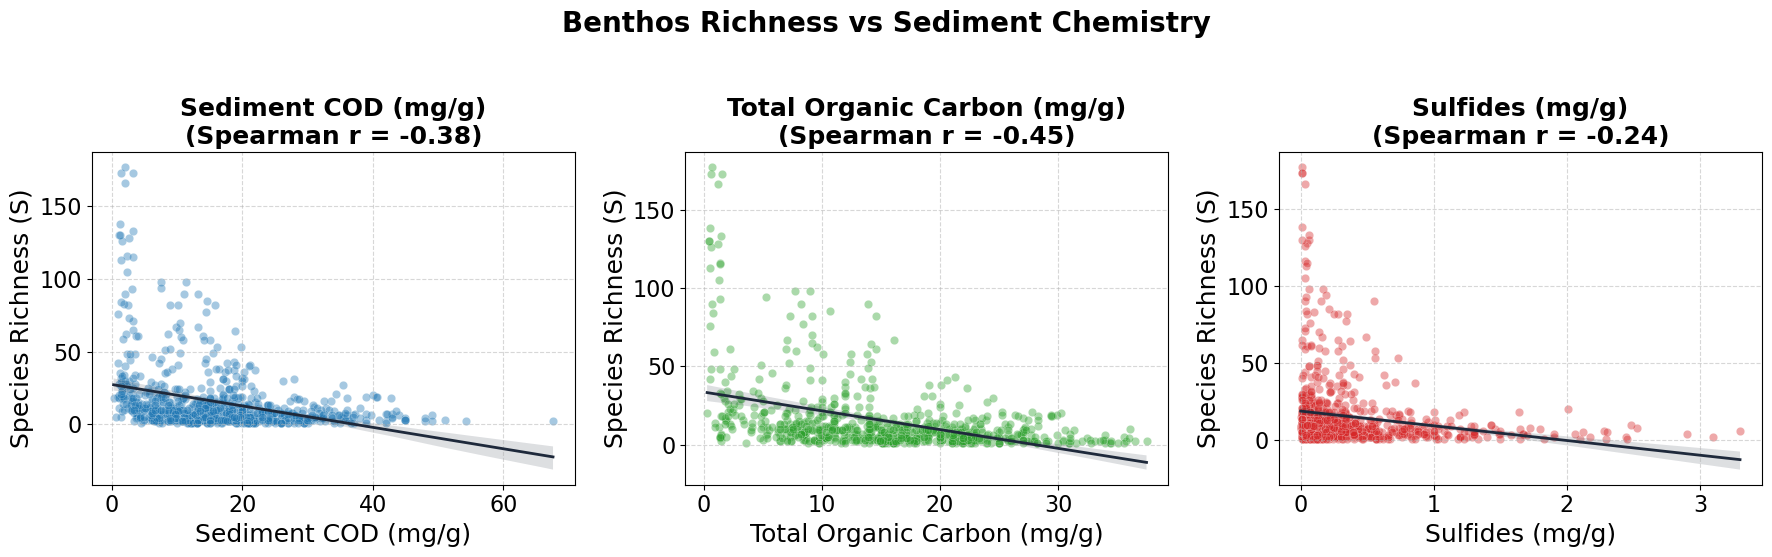

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
fig.suptitle('Benthos Richness vs Sediment Chemistry', y=1.02)

env_params = ['COD', 'TOC', '硫化物']
titles = ['Sediment COD (mg/g)', 'Total Organic Carbon (mg/g)', 'Sulfides (mg/g)']
colors = ['#1f77b4', '#2ca02c', '#d62728']

for idx, (param, title, color) in enumerate(zip(env_params, titles, colors)):
    ax = axes[idx]
    # Drop missing values
    subset = df_merged[[param, 'richness']].dropna()
    
    # Calculate Spearman Correlation
    corr_val = subset[param].corr(subset['richness'], method='spearman')
    
    # Regplot
    sns.regplot(
        data=subset, x=param, y='richness', ax=ax, 
        color=color, scatter_kws={'alpha': 0.4, 'edgecolor': 'w', 'linewidths': 0.3},
        line_kws={'color': '#1e293b', 'linewidth': 2}
    )
    ax.set_title(f'{title}\n(Spearman r = {corr_val:.2f})')
    ax.set_xlabel(title)
    ax.set_ylabel('Species Richness (S)')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(output_fig_dir / 'sediment_benthos_correlations.png', dpi=300)
plt.show()


### D. Benthos Taxonomic Dominance
We highlight the top 10 most dominant benthos taxa in terms of cumulative abundance and biomass weight.


/tmp/ipykernel_30927/2583329916.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_abundance, x='abundance', y='species_sci', ax=axes[0], palette='Blues_r')
/tmp/ipykernel_30927/2583329916.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_biomass, x='weight', y='species_sci', ax=axes[1], palette='Oranges_r')


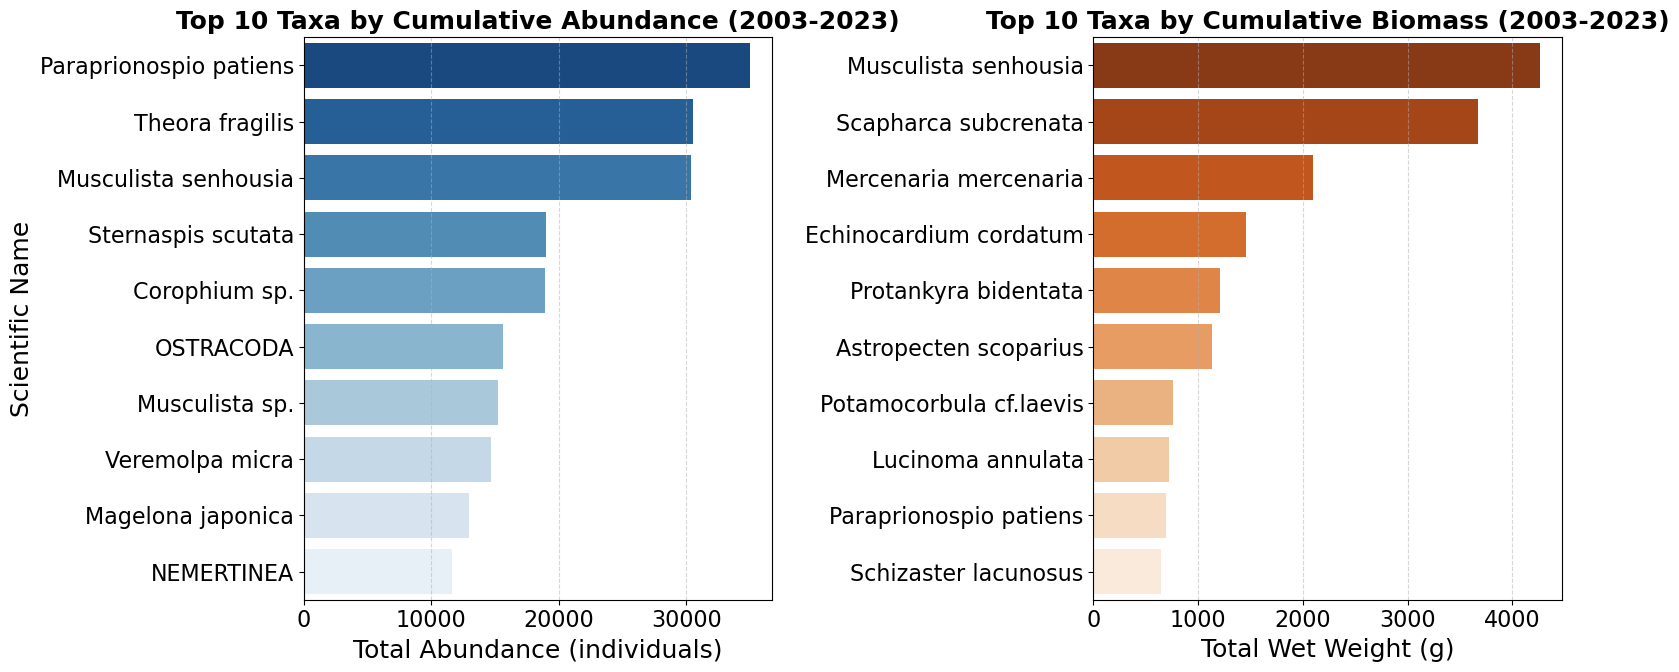

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Top 10 by abundance
top_abundance = df_species_agg.groupby('species_sci')['abundance'].sum().nlargest(10).reset_index()
sns.barplot(data=top_abundance, x='abundance', y='species_sci', ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 10 Taxa by Cumulative Abundance (2003-2023)')
axes[0].set_xlabel('Total Abundance (individuals)')
axes[0].set_ylabel('Scientific Name')
axes[0].grid(True, axis='x', linestyle='--', alpha=0.5)

# Top 10 by biomass
top_biomass = df_species_agg.groupby('species_sci')['weight'].sum().nlargest(10).reset_index()
sns.barplot(data=top_biomass, x='weight', y='species_sci', ax=axes[1], palette='Oranges_r')
axes[1].set_title('Top 10 Taxa by Cumulative Biomass (2003-2023)')
axes[1].set_xlabel('Total Wet Weight (g)')
axes[1].set_ylabel('')
axes[1].grid(True, axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(output_fig_dir / 'top_taxa_dominance.png', dpi=300)
plt.show()
